# Clinical Outcomes - Zhang et al


In [81]:
import os
import re
import sys
import pickle
import numpy as np
import pandas as pd
import scipy as sc
from scipy.stats import linregress, pearsonr, spearmanr, kendalltau, t
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb
from matplotlib import colormaps
from lmfit import minimize, Parameters
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import (test_progression, TruncateDataframe, ExtractTreatmentFromDf, calc_critical_treatment_threshold, GetPatientIDs,
                     calc_average_overshoot, calc_delta_benefit, predict_ct_ttp)
from fittingUtils import residual, compute_r_sq, load_fit, generate_fitSummaryDf
from plotUtils import PlotDrug, PlotData, convert_to_rgb_grayscale, redistribute_rgb
from odeModels import LotkaVolterraModel

In [82]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

In [83]:
file_path = os.path.dirname(os.path.abspath("__file__"))

RERUN_FITTING = True

In [84]:
def SimulateFit(fit_params, dataDf, dt=1, solver_kws={}):
    myModel = LotkaVolterraModel()
    myModel.SetParams(**fit_params)
    myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(dataDf),**solver_kws)
    # Interpolate to the desired time grid
    t_eval = np.arange(0, myModel.resultsDf.Time.max(), dt)
    trimmedResultsDic = {'Time': t_eval}
    for variable in ['S', 'R', 'TumourSize', 'DrugConcentration']:
        f = sc.interpolate.interp1d(myModel.resultsDf.Time, myModel.resultsDf[variable])
        trimmedResultsDic = {**trimmedResultsDic, variable: f(t_eval)}
    myModel.resultsDf = pd.DataFrame(trimmedResultsDic)
    return myModel

## Patient Datasets

In [85]:
# Overwrite helperS function for this dataA format
def LoadPatientData(patientId, dataDir):
    patientDataDf = pd.read_csv(os.path.join(dataDir, "patient%.3d.csv" % patientId))
    patientDataDf.drop(labels='PSA', axis=1, inplace=True)
    patientDataDf.rename({'Days': 'Time', 'Abi': 'DrugConcentration',
                          'relPSA_Indi': 'PSA'}, axis=1, inplace=True)
    patientDataDf = patientDataDf.sort_values(by="Time")
    return patientDataDf

Loaded Patient IDs: [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1009, 1010, 1011, 1012, 1014, 1015, 1016, 1017, 1018, 1020]


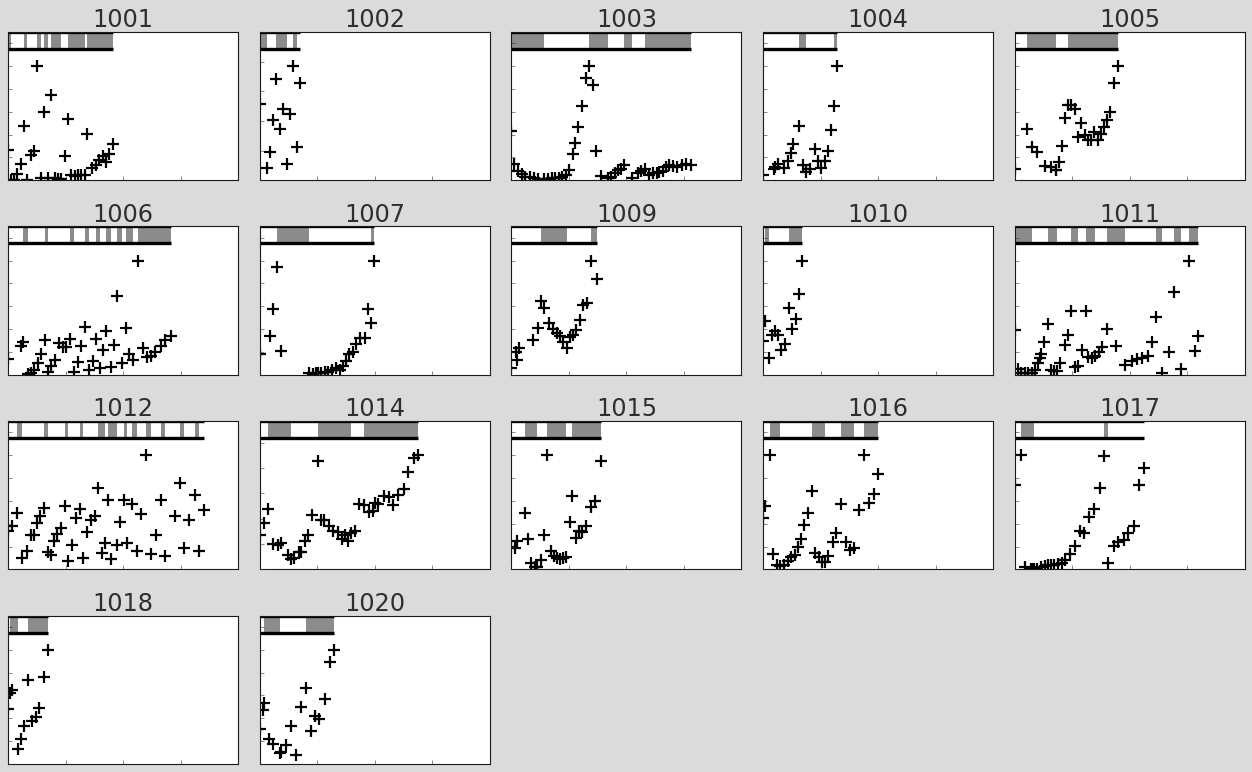

In [86]:
data_path = "../patients/Zhang_et_al/at_patients/data"
patientIds = GetPatientIDs(data_path)
print("Loaded Patient IDs: " + str(patientIds))


plt.rcParams['font.size'] = '18'; n_row=4
fig, axs = plt.subplots(n_row, int((len(patientIds)+(n_row-1))/n_row), figsize=(16, 10))
for i, patientId in enumerate(patientIds):
    dataDf = LoadPatientData(patientId, data_path)
    PlotData(dataDf, axs.flatten()[i], drugBarPosition=max(dataDf.PSA)*1.15,
             drugBarHeight=max(dataDf.PSA)*0.15)
    axs.flatten()[i].set_title(patientId)
    axs.flatten()[i].set_ylim(0, max(dataDf.PSA) * 1.3)
    axs.flatten()[i].set_xticklabels([]); axs.flatten()[i].set_yticklabels([])

for i in range(len(patientIds), axs.size):
    axs.flatten()[i].axis('off')
plt.tight_layout()
# plt.savefig("Zhang_et_al_patients.pdf")


In [87]:
def calculate_no_treatment_periods(patient_data):
    no_treatment_periods = []
    start_time = None
    in_no_treatment = False
    
    for index, row in patient_data.iterrows():
        if row['DrugConcentration'] == 0:
            if not in_no_treatment:
                in_no_treatment = True
                start_time = row['Time']
        else:
            if in_no_treatment:
                no_treatment_periods.append(row['Time'] - start_time)
                in_no_treatment = False
                start_time = None
    
    if in_no_treatment and start_time is not None:
        no_treatment_periods.append(patient_data['Time'].iloc[-1] - start_time)
    
    return no_treatment_periods

def average_no_treatment_periods(patient_data):
    no_treatment_periods = calculate_no_treatment_periods(patient_data)
    if no_treatment_periods:
        return np.mean(no_treatment_periods)
    else:
        return 0

average_no_treatment_durations = {}
for patientId in patientIds:
    dataDf = LoadPatientData(patientId, data_path)
    avg_duration = average_no_treatment_periods(dataDf)
    average_no_treatment_durations[patientId] = int(avg_duration)

print(average_no_treatment_durations)
print(f"Minimum average no treatment duration: {min(average_no_treatment_durations.values())}")
print(f"Maximum average no treatment duration: {max(average_no_treatment_durations.values())}")


{1001: 57, 1002: 56, 1003: 217, 1004: 278, 1005: 107, 1006: 91, 1007: 347, 1009: 234, 1010: 99, 1011: 107, 1012: 93, 1014: 139, 1015: 84, 1016: 140, 1017: 324, 1018: 53, 1020: 132}
Minimum average no treatment duration: 53
Maximum average no treatment duration: 347


## Fit to first cycle only

These parameter values can then subsequently be used for validation later.

In [88]:
patientsToAnalyseList = patientIds
out_dir = os.path.join(os.pardir, "patients", "Zhang_et_al", "All_Patients_Trunc")


solver_kws={'method':'RK45', 'absErr':1.0e-10, 'relErr':1.0e-10,
            'suppressOutputB':False}
optimiser_kws = {'method':'least_squares', 'xtol':1e-8, 'ftol':1e-8,
                 'max_nfev':200,'nan_policy':'omit', 'verbose':0}

# Model Parameters
model_name = "LotkaVolterraModel"; params = Parameters()
working_dir = os.path.join(out_dir, model_name)

# New
params.add('turnover', min=0.01, max=1., vary=True)
params.add('K', value=3, min=2.5, max=5, vary=True)

# Fixed from historical data/estimates
params.add('fR', value=1e-2, vary=False)
params.add('cost', value=0.01, vary=False)
params.add('rS', value=0.027, vary=False)
params.add('n0', value=0.1, vary=False)  # Will be matched to initial value

# Fixed/Calculated Parameters
params.add('rR', expr='(1-cost)*rS', vary=False)
params.add('dS', expr='turnover*rS', vary=False); params.add('dR', expr='dS', vary=False)
params.add('dD', value=1.5, vary=False); params.add('theta', value=1, vary=False)
params.add('D', value=1, vary=False); params.add('DMax', value=1, vary=False)
params.add('S0', expr='n0*(1-fR)', vary=False); params.add('R0', expr='n0*fR', vary=False)

In [89]:
if RERUN_FITTING:
    for patientId in tqdm(patientsToAnalyseList):
        # Load data
        training_data_df = LoadPatientData(patientId, data_path)
        training_data_df = training_data_df.dropna(subset=['PSA']).reset_index()       
        training_data_df = TruncateDataframe(training_data_df, drug_name='DrugConcentration')
        
        # Setup env
        curr_out_dir = os.path.join(working_dir,"patient%d"%patientId)
        os.makedirs(curr_out_dir, exist_ok=True)
        tmp_model = LotkaVolterraModel()
        curr_params = Parameters()
        curr_params.add_many(*[params[x] for x in params.keys()])

        # Set up initial conditions
        if params['n0'].vary==False: curr_params['n0'].value = training_data_df.PSA.iloc[0]

        # Fit
        tmp_model.SetParams(**params)
        fit_obj = minimize(residual, params, args=(training_data_df, tmp_model, 
                                                        "PSA", solver_kws), **optimiser_kws)
        fit_obj.fitId = 0
        fit_obj.numericalStabilisation = tmp_model.numericalStabilisationB
        fit_obj.modelName = model_name
        fit_obj.data = training_data_df
        fit_obj.rSq = compute_r_sq(fit_obj, training_data_df, feature="PSA")

        # Post-process
        pickle.dump(obj=fit_obj, file=open(os.path.join(curr_out_dir,
                                                        "fitObj_fit_%d.p"%(fit_obj.fitId)), "wb"))

100%|██████████| 17/17 [00:02<00:00,  7.38it/s]


In [90]:
# Store patient parameters in a dataframe
if RERUN_FITTING:
    trunc_df = pd.DataFrame()
    for patient_dir in os.listdir(os.path.join(out_dir, model_name)):
        fitSummaryDf = generate_fitSummaryDf(os.path.join(out_dir, model_name, patient_dir))
        fitSummaryDf.insert(0, "PatientId",  int(re.findall(r'\d+', patient_dir)[0]))
        trunc_df = pd.concat([trunc_df, fitSummaryDf], axis=0)
        
    trunc_df['TimeInTrial'] = trunc_df['PatientId'].apply(lambda x: \
        LoadPatientData(x, data_path).Time.max())
    trunc_df = trunc_df.sort_values(by="PatientId").reset_index()
    trunc_df = trunc_df[trunc_df['PatientId'].isin(patientIds)]
    trunc_df['Cost'] = 1 - trunc_df['rR'] / trunc_df['rS']; 
    trunc_df['Turnover'] = trunc_df['dS'] / trunc_df['rS']

    print(trunc_df[['PatientId', 'n0', 'fR', 'Turnover', 'Cost', 'K', 'rS', 'R0']])

    #Test progression
    trunc_df['Progression'] = trunc_df.apply(lambda x: test_progression(x.to_dict()), axis=1)
    print("Progression: %d/%d"%(trunc_df.Progression.sum(), len(trunc_df)), end='')
    print(f"  ({[x for x in trunc_df.PatientId[trunc_df.Progression==True]]})")

    # Save patient params
    trunc_df.to_csv("patient_fits/Zhang_first_cycle.csv", index=False)

    PatientId        n0    fR  Turnover  Cost         K     rS        R0
0        1001  0.264744  0.01  1.000000  0.01  5.000000  0.027  0.002647
1        1002  0.515128  0.01  0.319868  0.01  5.000000  0.027  0.005151
2        1003  0.432910  0.01  0.667075  0.01  5.000000  0.027  0.004329
3        1004  0.046110  0.01  0.718804  0.01  5.000000  0.027  0.000461
4        1005  0.096340  0.01  0.010000  0.01  3.000000  0.027  0.000963
5        1006  0.139619  0.01  0.722121  0.01  2.640343  0.027  0.001396
6        1007  0.183247  0.01  0.598594  0.01  5.000000  0.027  0.001832
7        1009  0.059104  0.01  0.610826  0.01  2.500000  0.027  0.000591
8        1010  0.293528  0.01  0.010000  0.01  3.000000  0.027  0.002935
9        1011  0.392857  0.01  0.407929  0.01  5.000000  0.027  0.003929
10       1012  0.338061  0.01  0.747566  0.01  2.627492  0.027  0.003381
11       1014  0.274187  0.01  0.611965  0.01  2.695977  0.027  0.002742
12       1015  0.194030  0.01  0.835285  0.01  5.00

/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_61005/1313451732.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  trunc_df = pd.concat([trunc_df, fitSummaryDf], axis=0)
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_61005/1313451732.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  trunc_df = pd.concat([trunc_df, fitSummaryDf], axis=0)
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_61005/1313451732.py:7: FutureWarning: The behavior of DataFrame concatenati

## Clinical Outcomes

In [91]:
def get_ttp(patientId, **kwargs):
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    dataDf = dataDf[dataDf['PSA'] < 1.2 * dataDf['PSA'].iloc[0]]
    return dataDf['Time'].iloc[-1]

get_ttp(1001)

np.int64(916)

In [92]:
def get_first_cycle_df(patient_id, data_path):
    df = LoadPatientData(patient_id, data_path).copy()
    df = df.sort_values("Time").reset_index(drop=True)

    # Prefer explicit cycle labels if available
    if "CycleId" in df.columns and df["CycleId"].notna().sum() > 0:
        c1 = df[df["CycleId"] == 1].copy()
        if len(c1) > 0:
            return c1.sort_values("Time").reset_index(drop=True)

    # Fallback: first contiguous treatment episode starting at first timepoint
    # (from first row until first change in DrugConcentration state and back)
    if "DrugConcentration" in df.columns:
        drug = df["DrugConcentration"].fillna(method="ffill").fillna(0.0).to_numpy()
        on = drug > 0
        # Define first cycle as all points until the first return to on after an off period
        seen_off = False
        end_idx = len(df) - 1
        for i in range(1, len(df)):
            if not on[i]:
                seen_off = True
            if seen_off and on[i]:
                end_idx = i - 1
                break
        return df.iloc[: end_idx + 1].copy().reset_index(drop=True)

    return df.copy().reset_index(drop=True)

In [93]:
def get_first_cycle_duration(patient_id, data_path):
    """Duration (days) of the first cycle: last minus first timepoint of the cycle-1 data."""
    c1 = get_first_cycle_df(patient_id, data_path)
    return c1["Time"].max() - c1["Time"].min()


def get_first_cycle_durations(patient_ids, data_path):
    """First-cycle duration for each patient, as a DataFrame."""
    return pd.DataFrame({
        "PatientId": patient_ids,
        "FirstCycleDuration": [get_first_cycle_duration(pid, data_path) for pid in patient_ids],
    })


first_cycle_durations = get_first_cycle_durations(patientIds, data_path)
print(first_cycle_durations)
print(first_cycle_durations["FirstCycleDuration"].describe())


    PatientId  FirstCycleDuration
0        1001                 110
1        1002                 119
2        1003                 649
3        1004                 262
4        1005                 439
5        1006                 109
6        1007                 116
7        1009                 235
8        1010                 194
9        1011                 258
10       1012                  38
11       1014                  41
12       1015                  46
13       1016                  15
14       1017                 737
15       1018                 137
16       1020                  31
count     17.000000
mean     208.000000
std      213.082437
min       15.000000
25%       46.000000
50%      119.000000
75%      258.000000
max      737.000000
Name: FirstCycleDuration, dtype: float64


/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_61005/3574561312.py:14: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  drug = df["DrugConcentration"].fillna(method="ffill").fillna(0.0).to_numpy()
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_61005/3574561312.py:14: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  drug = df["DrugConcentration"].fillna(method="ffill").fillna(0.0).to_numpy()
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_61005/3574561312.py:14: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  drug = df["DrugConcentration"].fillna(method="ffill").fillna(0.0).to_numpy()
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_61005/3574561312.py:14: FutureWarning: Series.fillna wit

In [94]:
def get_N_star(patientId, **kwargs):
    ttp = get_ttp(patientId, **kwargs)
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    dataDf = dataDf[dataDf['Time'] <= ttp]

    N_star = dataDf['PSA'].mean()
    interval = dataDf['Time'].diff().mean()
    overshoot = calc_average_overshoot(int(interval), N_star, **kwargs)
    return N_star + overshoot

def predict_at_threshold_ttp(n_crit, **kwargs):
    params = kwargs
    benefit = calc_delta_benefit(kappa=n_crit / params['K'], **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

def calc_AT_score(patientId, **kwargs):
    params = kwargs
    n_crit = get_N_star(patientId, **params)
    # return calc_delta_benefit(kappa=n_crit / params['K'], **params)
    return calc_delta_benefit(kappa=0.2, **params)

In [95]:
def predict_ct_ttp(n_lim=None, **kwargs):
    # This is in the absence of sensitive cells
    params = kwargs
    if n_lim is None: n_lim = params['n0'] * 1.2
    
    factor = params['rR'] - params['dR']
    log_num = params['rR'] - factor * (params['K'] / params['R0'])
    log_den = params['rR'] - factor * (params['K'] / n_lim)
    return np.log(log_num / log_den) / factor

In [96]:
# Generate a table with patient id, predicted AT TTP
TTP_data = []
param_sets = [trunc_df]

patientIds = [x for x in patientIds if x in trunc_df.PatientId[trunc_df.Progression==True].values]


for patientId in tqdm(patientIds):
    param_set = trunc_df.loc[trunc_df.PatientId == patientId].iloc[0].to_dict()
    
    try:
        ct_perfect_preds = int(predict_ct_ttp(**param_set))
        at_scores = calc_AT_score(patientId, **param_set)
        clinical_preds = int(predict_at_threshold_ttp(param_set['n0'] * get_N_star(patientId, **param_set), **param_set))
        clinical_ttps = int(get_ttp(patientId))
        
        TTP_data.append([patientId, trunc_df.loc[trunc_df.PatientId == patientId].iloc[0]['RSquared'],
                         ct_perfect_preds, at_scores, clinical_preds, clinical_ttps])
    except Exception as e:
        # print(f"**Error processing patient {patientId}: {e}")
        continue

at_ttp_df = pd.DataFrame(TTP_data, columns=['PatientId', 'RSquared', 'CT_Perfect', 'AT_Score', 'Clinical_Preds', 'Clinical_TTP'])
at_ttp_df = at_ttp_df[at_ttp_df['RSquared'].isna() | (at_ttp_df['RSquared'] > 0.5)]


100%|██████████| 16/16 [00:00<00:00, 310.37it/s]


In [97]:

# Linear regression
slope, intercept, r_value, p_value_linear, std_err = linregress(
    at_ttp_df['AT_Score'], at_ttp_df['Clinical_TTP']
)
print(f"Number of patients included in analysis: {len(at_ttp_df)}")

# slope uncertainty = standard error from linregress
print("Linear Regression:")
print(f"  R² = {r_value**2:.4f}")
print(f"  p-value = {p_value_linear:.4f}")


Number of patients included in analysis: 13
Linear Regression:
  R² = 0.4058
  p-value = 0.0192


In [98]:
# Linear regression
slope, intercept, r_value, p_value_linear, std_err = linregress(
    at_ttp_df['Clinical_Preds'], at_ttp_df['Clinical_TTP']
)
print(f"Number of patients included in analysis: {len(at_ttp_df)}")

# slope uncertainty = standard error from linregress
print("Linear Regression:")
print(f"  R² = {r_value**2:.4f}")
print(f"  p-value = {p_value_linear:.4f}")


Number of patients included in analysis: 13
Linear Regression:
  R² = 0.4662
  p-value = 0.0101


In [99]:
from lifelines.statistics import logrank_test

# Patients included vs excluded from at_ttp_df
included_ids = set(at_ttp_df['PatientId'].values)
excluded_ids = [pid for pid in GetPatientIDs(data_path) if pid not in included_ids]
included_ids = list(included_ids)

# Get time in trial for each group
included_times = trunc_df[trunc_df['PatientId'].isin(included_ids)]['TimeInTrial'].values
excluded_times = trunc_df[trunc_df['PatientId'].isin(excluded_ids)]['TimeInTrial'].values

# Compute median, Q1, Q3
included_median = np.median(included_times)
included_q1, included_q3 = np.percentile(included_times, [25, 75])

excluded_median = np.median(excluded_times)
excluded_q1, excluded_q3 = np.percentile(excluded_times, [25, 75])

print(
    f"Included in at_ttp_df (n={len(included_ids)}): "
    f"Median={included_median:.0f}, Q1={included_q1:.0f}, Q3={included_q3:.0f}"
)
print(
    f"Excluded from at_ttp_df (n={len(excluded_ids)}): "
    f"Median={excluded_median:.0f}, Q1={excluded_q1:.0f}, Q3={excluded_q3:.0f}"
)

# Log-rank test using lifelines
included_events = np.ones(len(included_times), dtype=int)
excluded_events = np.ones(len(excluded_times), dtype=int)

results = logrank_test(included_times, excluded_times, included_events, excluded_events)
print(f"\nLog-Rank Test:")
print(f"  Test statistic: {results.test_statistic:.4f}")
print(f"  p-value: {results.p_value:.4f}")

Included in at_ttp_df (n=13): Median=1003, Q1=649, Q3=1419
Excluded from at_ttp_df (n=4): Median=762, Q1=719, Q3=813

Log-Rank Test:
  Test statistic: 2.9684
  p-value: 0.0849


In [100]:
# Average number of PSA measurements and average inter-measurement gap by group

def _measurement_stats_for_patient(pid):
    df = LoadPatientData(int(pid), data_path).copy()
    df = df[df["PSA"].notna()].sort_values("Time")
    n_meas = len(df)
    avg_gap = df["Time"].diff().dropna().mean() if n_meas > 1 else np.nan
    return n_meas, avg_gap

def _group_measurement_summary(id_list, group_name):
    rows = []
    for pid in id_list:
        n_meas, avg_gap = _measurement_stats_for_patient(pid)
        rows.append({
            "PatientId": int(pid),
            "Group": group_name,
            "N_measurements": n_meas,
            "Avg_gap_days": avg_gap
        })
    out = pd.DataFrame(rows)
    return out

included_meas_df = _group_measurement_summary(included_ids, "Included")
excluded_meas_df = _group_measurement_summary(excluded_ids, "Excluded")
meas_df = pd.concat([included_meas_df, excluded_meas_df], ignore_index=True)

summary_df = (
    meas_df.groupby("Group", as_index=False)
    .agg(
        N_patients=("PatientId", "count"),
        Avg_N_measurements=("N_measurements", "mean"),
        Avg_gap_days=("Avg_gap_days", "mean")
    )
)

print(summary_df.to_string(index=False))

# Statistical comparison: Included vs Excluded
alpha = 0.05

def compare_groups(meas_df, col, alpha=0.05):
    inc = meas_df.loc[meas_df["Group"] == "Included", col].dropna().to_numpy()
    exc = meas_df.loc[meas_df["Group"] == "Excluded", col].dropna().to_numpy()

    # Welch t-test (unequal variances)
    t_res = sc.stats.ttest_ind(inc, exc, equal_var=False, nan_policy="omit")

    # Mann–Whitney U (non-parametric; safer for small n)
    u_res = sc.stats.mannwhitneyu(inc, exc, alternative="two-sided")

    print(f"\n{col}")
    print(f"  Included mean={inc.mean():.3f} (n={len(inc)})")
    print(f"  Excluded mean={exc.mean():.3f} (n={len(exc)})")
    print(f"  Welch t-test p={t_res.pvalue:.4f} -> "
          f"{'significant' if t_res.pvalue < alpha else 'not significant'}")
    print(f"  Mann-Whitney U p={u_res.pvalue:.4f} -> "
          f"{'significant' if u_res.pvalue < alpha else 'not significant'}")

compare_groups(meas_df, "N_measurements", alpha=alpha)
compare_groups(meas_df, "Avg_gap_days", alpha=alpha)

   Group  N_patients  Avg_N_measurements  Avg_gap_days
Excluded           4           25.000000     32.494766
Included          13           29.846154     35.107593

N_measurements
  Included mean=29.846 (n=13)
  Excluded mean=25.000 (n=4)
  Welch t-test p=0.3050 -> not significant
  Mann-Whitney U p=0.6099 -> not significant

Avg_gap_days
  Included mean=35.108 (n=13)
  Excluded mean=32.495 (n=4)
  Welch t-test p=0.1532 -> not significant
  Mann-Whitney U p=0.1303 -> not significant


# Other PSA_based Metrics

In [101]:
def _pick_psa_column(df):
    if "PSA_raw" in df.columns and df["PSA_raw"].notna().sum() > 0:
        return "PSA_raw"
    return "PSA"

def _safe_linregress(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 2:
        return np.nan, np.nan, np.nan  # slope, intercept, pvalue
    if np.allclose(x, x[0]) or np.allclose(y, y[0]):
        return np.nan, np.nan, np.nan
    res = linregress(x, y)
    return res.slope, res.intercept, res.pvalue


In [102]:
def compute_first_cycle_metrics(patient_id, data_path):
    c1 = get_first_cycle_df(patient_id, data_path)
    psa_col = _pick_psa_column(c1)

    # Keep only valid rows for metric calculations
    c1v = c1[["Time", psa_col] + ([ "DrugConcentration" ] if "DrugConcentration" in c1.columns else [])].copy()
    c1v = c1v.dropna(subset=["Time", psa_col]).sort_values("Time")
    c1v = c1v.groupby("Time", as_index=False).mean(numeric_only=True)  # handles duplicate times

    out = {
        "PatientId": patient_id,
        "Baseline_Tumor_Burden": np.nan,
        "PSA_Nadir": np.nan,
        "Time_to_Nadir": np.nan,
        "PSA_Velocity_per_day": np.nan,
        "PSA_Velocity_per_month": np.nan,
        "PSA_Doubling_Time_days": np.nan,
        "Regrowth_n_points": 0
    }

    if len(c1v) == 0:
        return out

    # Baseline tumor burden: first observed PSA in first cycle
    t0 = float(c1v["Time"].iloc[0])
    p0 = float(c1v[psa_col].iloc[0])
    out["Baseline_Tumor_Burden"] = p0

    # Nadir and time to nadir
    nadir_idx = int(np.nanargmin(c1v[psa_col].to_numpy(dtype=float)))
    t_nadir = float(c1v["Time"].iloc[nadir_idx])
    p_nadir = float(c1v[psa_col].iloc[nadir_idx])

    out["PSA_Nadir"] = p_nadir
    out["Time_to_Nadir"] = t_nadir - t0

    # Regrowth window: from nadir to cycle end, ideally off-treatment only
    reg = c1v[c1v["Time"] >= t_nadir].copy()

    if "DrugConcentration" in reg.columns:
        off = reg[reg["DrugConcentration"].fillna(0.0) <= 0].copy()
        # If too few off-treatment points, fallback to nadir->end points
        if len(off) >= 2:
            reg = off

    # Need at least 2 points for slopes
    if len(reg) < 2:
        return out

    x = reg["Time"].to_numpy(dtype=float)
    y = reg[psa_col].to_numpy(dtype=float)

    # Raw linear slope: off-treatment regrowth slope and PSA velocity
    slope_lin, intercept_lin, p_lin = _safe_linregress(x, y)
    out["Regrowth_Slope_per_day"] = slope_lin
    out["PSA_Velocity_per_day"] = slope_lin
    out["PSA_Velocity_per_month"] = slope_lin * 30.437 if np.isfinite(slope_lin) else np.nan
    out["Regrowth_n_points"] = len(reg)

    # PSA doubling time from log-linear regression over regrowth PSA
    pos = y > 0
    if np.sum(pos) >= 2:
        slope_log, intercept_log, p_log = _safe_linregress(x[pos], np.log(y[pos]))
        if np.isfinite(slope_log) and slope_log > 0:
            out["PSA_Doubling_Time_days"] = np.log(2.0) / slope_log
        else:
            out["PSA_Doubling_Time_days"] = np.nan  # flat/declining or ill-defined
    else:
        out["PSA_Doubling_Time_days"] = np.nan

    return out

In [103]:
metric_rows = []
for pid in patientIds:
    metric_rows.append(compute_first_cycle_metrics(pid, data_path))

metrics_df = pd.DataFrame(metric_rows).sort_values("PatientId").reset_index(drop=True)

bench_df = pd.merge(metrics_df, at_ttp_df, on="PatientId", how="inner")


/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_61005/3574561312.py:14: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  drug = df["DrugConcentration"].fillna(method="ffill").fillna(0.0).to_numpy()
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_61005/3574561312.py:14: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  drug = df["DrugConcentration"].fillna(method="ffill").fillna(0.0).to_numpy()
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_61005/3574561312.py:14: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  drug = df["DrugConcentration"].fillna(method="ffill").fillna(0.0).to_numpy()
/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_61005/3574561312.py:14: FutureWarning: Series.fillna wit

In [104]:
bench_df = pd.merge(bench_df, first_cycle_durations, on="PatientId", how="left")

# Clinical event time minus first-cycle duration; NaN where the event precedes the end of the first cycle
bench_df["TTP_minus_FirstCycle"] = bench_df["Clinical_TTP"] - bench_df["FirstCycleDuration"]
bench_df["NegativeTTPAfterCycle"] = bench_df["TTP_minus_FirstCycle"] < 0
bench_df.loc[bench_df["NegativeTTPAfterCycle"], "TTP_minus_FirstCycle"] = np.nan

# Use the "TTP_minus_FirstCycle" as an alternate event to exclude first cycle 
# This is used to compute stats in response to Mistry (2026)



In [105]:
def correlation_report(df, metric_cols, target_cols):
    rows = []
    for m in metric_cols:
        for t in target_cols:
            sub = df[[m, t]].dropna()
            n = len(sub)
            if n < 3:
                rows.append({
                    "Metric": m, "Target": t, "N": n,
                    "Pearson_r": np.nan, "Pearson_R2": np.nan, "Pearson_p": np.nan,
                    "Spearman_rho": np.nan, "Spearman_p": np.nan,
                    "Kendall_tau": np.nan, "Kendall_p": np.nan
                })
                continue

            x = sub[m].to_numpy(dtype=float)
            y = sub[t].to_numpy(dtype=float)

            pr, pp = pearsonr(x, y)
            sr, sp = spearmanr(x, y)
            kt, kp = kendalltau(x, y)

            rows.append({
                "Metric": m, "Target": t, "N": n,
                "Pearson_r": pr, "Pearson_R2": pr**2, "Pearson_p": pp,
                "Spearman_rho": sr, "Spearman_p": sp,
                "Kendall_tau": kt, "Kendall_p": kp
            })

    return pd.DataFrame(rows)

In [124]:
metric_cols = [
    "AT_Score",
    "Clinical_Preds",
    "PSA_Doubling_Time_days",
    "PSA_Nadir",
    "Time_to_Nadir",
    "PSA_Velocity_per_day",
    "Baseline_Tumor_Burden"
]

# Choose targets you want to benchmark against
target_cols = ["TTP_minus_FirstCycle"]  # add others if desired, e.g. "Clinical_Preds", "Match_Preds"

corr_df = correlation_report(bench_df, metric_cols, target_cols)
print(corr_df.sort_values(["Target", "Metric"]).to_string(index=False))

                Metric               Target  N  Pearson_r  Pearson_R2  Pearson_p  Spearman_rho  Spearman_p  Kendall_tau  Kendall_p
              AT_Score TTP_minus_FirstCycle 12   0.749136    0.561205   0.005043      0.867133    0.000260     0.757576   0.000240
 Baseline_Tumor_Burden TTP_minus_FirstCycle 12  -0.301591    0.090957   0.340759     -0.286713    0.366251    -0.212121   0.380705
        Clinical_Preds TTP_minus_FirstCycle 12   0.790038    0.624160   0.002232      0.888112    0.000114     0.787879   0.000107
PSA_Doubling_Time_days TTP_minus_FirstCycle 12  -0.196301    0.038534   0.540892      0.097902    0.762122     0.090909   0.737306
             PSA_Nadir TTP_minus_FirstCycle 12   0.187556    0.035177   0.559411      0.181818    0.571701     0.121212   0.638361
  PSA_Velocity_per_day TTP_minus_FirstCycle 12  -0.220437    0.048593   0.491163     -0.118881    0.712884    -0.121212   0.638361
         Time_to_Nadir TTP_minus_FirstCycle 12  -0.039146    0.001532   0.903860   

## Accounting for absence of progression

This can be conducted against eTTP as all patients reached biochemical progression during the trial

In [107]:
def biochemical_progression_status(patientId, **kwargs):
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    return dataDf['PSA'].max() > 1.2 * dataDf['PSA'].iloc[0]

In [126]:
# Install lifelines if needed: pip install lifelines
from lifelines import CoxPHFitter
import warnings


cox_covariates = [
    "Baseline_Tumor_Burden",
    "PSA_Nadir",
    "Time_to_Nadir",
    "PSA_Doubling_Time_days",
    # 'Clinical_Preds'
    "AT_Score"
]

cox_labels = {
    "Baseline_Tumor_Burden": "Baseline PSA",
    "PSA_Nadir": "PSA Nadir",
    "Time_to_Nadir": "Time to Nadir (days)",
    "PSA_Doubling_Time_days": "PSA Doubling Time (days)",
    # "Clinical_Preds": "Clinical Predictions"
    "AT_Score": "AT Score"
}

duration_col = "TTP_minus_FirstCycle"
event_col    = "Event"         

bench_df[event_col] = bench_df.apply(lambda row: 1 if biochemical_progression_status(row.PatientId) else 0, axis=1)
cox_df = bench_df[cox_covariates + [duration_col, event_col]].dropna().copy()
# Standardise covariates so HRs are interpretable and the fitter is stable
cox_df_scaled = cox_df.copy()
for col in cox_covariates:
    sd = cox_df_scaled[col].std()
    if sd > 0:
        cox_df_scaled[col] = (cox_df_scaled[col] - cox_df_scaled[col].mean()) / sd

print(f"Cox regression dataset: {len(cox_df)} patients, {len(cox_covariates)} covariates")
print(cox_df[[duration_col, event_col] + cox_covariates].to_string(index=False))

Cox regression dataset: 12 patients, 5 covariates
 TTP_minus_FirstCycle  Event  Baseline_Tumor_Burden  PSA_Nadir  Time_to_Nadir  PSA_Doubling_Time_days  AT_Score
                202.0      1               0.515128   0.078980           64.0               23.192723  0.420686
                913.0      1               0.432910   0.010310          322.0               46.339533  1.600809
               1096.0      1               0.139619   0.139619            0.0              125.548165  2.864461
                691.0      1               0.183247   0.183247            0.0               76.041909  1.026534
                  0.0      1               0.293528   0.150555           50.0              535.670044  0.253650
               1333.0      1               0.392857   0.014610          114.0               25.713716  0.517040
               1619.0      1               0.338061   0.338061            0.0              222.158786  4.648728
                784.0      1               0.274187   

In [127]:
# --- Univariable Cox regressions ---
uni_results = {}

model_outputs = []
for cov in cox_covariates:
    sub = cox_df_scaled[[cov, duration_col, event_col]].dropna()
    cph = CoxPHFitter() 
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cph.fit(sub, duration_col=duration_col, event_col=event_col, show_progress=False)
    s = cph.summary
    uni_results[cov] = {
        "HR":    float(s.loc[cov, "exp(coef)"]),
        "HR_lo": float(s.loc[cov, "exp(coef) lower 95%"]),
        "HR_hi": float(s.loc[cov, "exp(coef) upper 95%"]),
        "p":     float(s.loc[cov, "p"]),
    }
    model_outputs.append(cph)

print("Univariable models fitted.")

Univariable models fitted.


In [128]:
# --- Multivariable Cox regression ---
cph_multi = CoxPHFitter(penalizer=1.0)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    cph_multi.fit(
        cox_df_scaled[cox_covariates + [duration_col, event_col]],
        duration_col=duration_col,
        event_col=event_col,
        show_progress=False
    )

multi_results = {}
s = cph_multi.summary
for cov in cox_covariates:
    multi_results[cov] = {
        "HR":    float(s.loc[cov, "exp(coef)"]),
        "HR_lo": float(s.loc[cov, "exp(coef) lower 95%"]),
        "HR_hi": float(s.loc[cov, "exp(coef) upper 95%"]),
        "p":     float(s.loc[cov, "p"]),
    }

print("Multivariable model fitted.")

Multivariable model fitted.


In [129]:
import pandas as pd

rows = []
for cov in cox_covariates:
    u = uni_results[cov]
    m = multi_results[cov]
    
    rows.append({
        "Variable": cox_labels[cov],
        "Univariable HR (95% CI)": f"{u['HR']:.2f} ({u['HR_lo']:.2f}\u2013{u['HR_hi']:.2f})",
        "Univariable p": "<0.001" if u["p"] < 0.001 else f"{u['p']:.3f}",
        "Multivariable HR (95% CI)": f"{m['HR']:.2f} ({m['HR_lo']:.2f}\u2013{m['HR_hi']:.2f})",
        "Multivariable p": "<0.001" if m["p"] < 0.001 else f"{m['p']:.3f}"
    })

table_df = pd.DataFrame(rows)
print(table_df.to_string(index=False))

# Warn about sample size
print(f"\n N={len(cox_df)} patients.")
print("HR < 1 = longer TTP (protective); HR > 1 = shorter TTP (harmful).")

                Variable Univariable HR (95% CI) Univariable p Multivariable HR (95% CI) Multivariable p
            Baseline PSA        1.42 (0.68–2.95)         0.345          1.09 (0.68–1.73)           0.724
               PSA Nadir        0.86 (0.48–1.54)         0.612          0.97 (0.63–1.48)           0.879
    Time to Nadir (days)        1.03 (0.60–1.77)         0.904          0.96 (0.61–1.49)           0.840
PSA Doubling Time (days)        1.16 (0.42–3.21)         0.777          1.16 (0.69–1.95)           0.577
                AT Score        0.38 (0.14–1.05)         0.061          0.70 (0.46–1.09)           0.113

 N=12 patients.
HR < 1 = longer TTP (protective); HR > 1 = shorter TTP (harmful).


In [112]:
'''
\begin{table}[htbp]
\centering
\caption{Univariable and Multivariable Cox Proportional Hazards Analysis of Time to Progression ($N=15$)}
\label{tab:cox_analysis_new_cohort}
\begin{tabular}{l c c c c}
\toprule
\textbf{Variable} & \textbf{Univariable HR (95\% CI)} & \textit{\textbf{P}} \textbf{Value} & \textbf{Multivariable HR (95\% CI)} & \textit{\textbf{P}} \textbf{Value} \\
\midrule
Baseline PSA & 0.83 (0.44--1.54) & .55 & 0.87 (0.59--1.28) & .48 \\
PSA Nadir & 0.95 (0.59--1.53) & .83 & 1.03 (0.71--1.50) & .87 \\
Time to Nadir, d & 1.13 (0.64--1.97) & .68 & 1.02 (0.68--1.53) & .92 \\
PSA Doubling Time, d & 1.03 (0.40--2.64) & .95 & 1.11 (0.70--1.77) & .65 \\
Clinical Predictions & 0.45 (0.21--0.95) & .04 & 0.70 (0.47--1.03) & .07 \\
\bottomrule
\end{tabular}

\vspace{1ex}
{\raggedright \footnotesize \textit{Abbreviations:} CI, confidence interval; HR, hazard ratio; PSA, prostate-specific antigen. \par}
\end{table}
'''

'\n\x08egin{table}[htbp]\n\\centering\n\\caption{Univariable and Multivariable Cox Proportional Hazards Analysis of Time to Progression ($N=15$)}\n\\label{tab:cox_analysis_new_cohort}\n\x08egin{tabular}{l c c c c}\n\toprule\n\textbf{Variable} & \textbf{Univariable HR (95\\% CI)} & \textit{\textbf{P}} \textbf{Value} & \textbf{Multivariable HR (95\\% CI)} & \textit{\textbf{P}} \textbf{Value} \\\n\\midrule\nBaseline PSA & 0.83 (0.44--1.54) & .55 & 0.87 (0.59--1.28) & .48 \\\nPSA Nadir & 0.95 (0.59--1.53) & .83 & 1.03 (0.71--1.50) & .87 \\\nTime to Nadir, d & 1.13 (0.64--1.97) & .68 & 1.02 (0.68--1.53) & .92 \\\nPSA Doubling Time, d & 1.03 (0.40--2.64) & .95 & 1.11 (0.70--1.77) & .65 \\\nClinical Predictions & 0.45 (0.21--0.95) & .04 & 0.70 (0.47--1.03) & .07 \\\n\x08ottomrule\n\\end{tabular}\n\n\x0bspace{1ex}\n{\raggedright \x0cootnotesize \textit{Abbreviations:} CI, confidence interval; HR, hazard ratio; PSA, prostate-specific antigen. \\par}\n\\end{table}\n'


--- Testing Proportional Hazards Assumption ---

   Bootstrapping lowess lines. May take a moment...



/Users/kitgallagher/micromamba/envs/general_science/lib/python3.11/site-packages/lifelines/utils/lowess.py:54: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 5.551115123125784e-17.
  beta = linalg.solve(A, b, assume_a="pos", check_finite=False)
/Users/kitgallagher/micromamba/envs/general_science/lib/python3.11/site-packages/lifelines/utils/lowess.py:54: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 5.336965437486975e-17.
  beta = linalg.solve(A, b, assume_a="pos", check_finite=False)


Proportional hazard assumption looks okay.


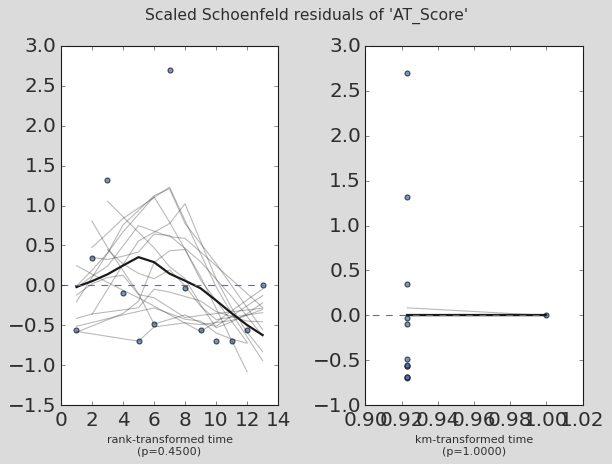

In [113]:
print("\n--- Testing Proportional Hazards Assumption ---")
# sub = cox_df_scaled[["Clinical_Preds", duration_col, event_col]].dropna()
sub = cox_df_scaled[["AT_Score", duration_col, event_col]].dropna()
cph.check_assumptions(sub, p_value_threshold=0.05, show_plots=True);

## Clinical Comparison

In [114]:
def clean_zhang_clinical_data(filepath):
    # Load the specific sheet
    df = pd.read_excel(filepath, sheet_name='Sheet2')
    
    # Helper function to parse columns with '>' or text
    def parse_event_time(row, col_name, fallback_col='on study (months)'):
        val = row[col_name]
        
        # If it's already a clean number, the event happened
        if isinstance(val, (int, float)) and not pd.isna(val):
            return val, 1
            
        val_str = str(val).strip()
        
        # If it contains '>', it's right-censored at that number
        if '>' in val_str:
            clean_num = float(val_str.replace('>', '').strip())
            return clean_num, 0
        
        # If it contains a trailing asterisk (e.g., "12.4*"), remove it and parse as numeric
        if '*' in val_str:
            clean_str = val_str.replace('*', '').strip()
            try:
                return float(clean_str), 1
            except ValueError:
                pass
            
        # If it's text (e.g., "Alive", "Not reached"), censor at last follow-up
        if val_str.replace('.', '', 1).isalpha() or 'Not' in val_str or pd.isna(val):
            return float(row[fallback_col]), 0
            
        return np.nan, 0

    # Apply parsing to OS and rPFS
    df[['OS_time', 'OS_event']] = df.apply(
        lambda row: pd.Series(parse_event_time(row, 'OS (months)')), axis=1
    )
    df[['rPFS_time', 'rPFS_event']] = df.apply(
        lambda row: pd.Series(parse_event_time(row, 'rPFS (months)')), axis=1
    )
    
    return df

In [115]:
# --- Execution ---
# 1. Clean the data
clinical_df = clean_zhang_clinical_data('../patients/Zhang_et_al/Adaptive abi_Subject outcomes with OS update 050326.xlsx')

nan_mask = clinical_df["Subject ID"].isna()
if nan_mask.any():
    first_nan_pos = np.where(nan_mask.to_numpy())[0][0]
    clinical_df = clinical_df.iloc[:first_nan_pos].copy()

clinical_df = clinical_df.dropna(axis=1, how="all")
clinical_df = clinical_df.rename(columns={"Subject ID": "PatientId"})


In [116]:
# 2. Merge with your biomarker predictions (assuming you have a predictions_df)
merged_df = clinical_df.merge(bench_df, on='PatientId')



In [117]:
# 3. Fit Univariable Cox Models for OS
cph_os = CoxPHFitter()
cph_os.fit(merged_df[['AT_Score', 'OS_time', 'OS_event']], duration_col='OS_time', event_col='OS_event')
print(cph_os.summary)

               coef  exp(coef)  se(coef)  coef lower 95%  coef upper 95%  \
covariate                                                                  
AT_Score  -0.435663   0.646836  0.313616       -1.050339        0.179012   

           exp(coef) lower 95%  exp(coef) upper 95%  cmp to         z  \
covariate                                                               
AT_Score              0.349819             1.196035     0.0 -1.389163   

                  p  -log2(p)  
covariate                      
AT_Score   0.164783   2.60136  


In [118]:
# 3. Fit Univariable Cox Models for OS
cph_os = CoxPHFitter()
cph_os.fit(merged_df[['Clinical_Preds', 'OS_time', 'OS_event']], duration_col='OS_time', event_col='OS_event')
print(cph_os.summary)

                    coef  exp(coef)  se(coef)  coef lower 95%  coef upper 95%  \
covariate                                                                       
Clinical_Preds -0.002564   0.997439  0.001442        -0.00539        0.000261   

                exp(coef) lower 95%  exp(coef) upper 95%  cmp to         z  \
covariate                                                                    
Clinical_Preds             0.994625             1.000262     0.0 -1.778587   

                       p  -log2(p)  
covariate                           
Clinical_Preds  0.075308  3.731063  


In [119]:
from lifelines import CoxPHFitter
from lifelines.statistics import logrank_test

# ---------------------------------------------------------
# 1. Approach 1: Continuous Cox Models on rPFS
# ---------------------------------------------------------
print("--- rPFS Continuous Cox: AT Score ---")
cph_rpfs_at = CoxPHFitter()
cph_rpfs_at.fit(merged_df[['AT_Score', 'rPFS_time', 'rPFS_event']], duration_col='rPFS_time', event_col='rPFS_event')
cph_rpfs_at.print_summary()

print("\n--- rPFS Continuous Cox: eTTP (Clinical_Preds) ---")
cph_rpfs_ettp = CoxPHFitter()
cph_rpfs_ettp.fit(merged_df[['Clinical_Preds', 'rPFS_time', 'rPFS_event']], duration_col='rPFS_time', event_col='rPFS_event')
cph_rpfs_ettp.print_summary()



--- rPFS Continuous Cox: AT Score ---


<lifelines.CoxPHFitter: fitted with 13 total observations, 2 right-censored observations>
             duration col = 'rPFS_time'
                event col = 'rPFS_event'
      baseline estimation = breslow
   number of observations = 13
number of events observed = 11
   partial log-likelihood = -18.12
         time fit was run = 2026-11-04 20:02:41 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
AT_Score  -0.57      0.57      0.36           -1.27            0.14                0.28                1.15

           cmp to     z    p  -log2(p)
covariate                             
AT_Score     0.00 -1.57 0.12      3.11
---
Concordance = 0.71
Partial AIC = 38.25
log-likelihood ratio test = 4.06 on 1 df
-log2(p) of ll-ratio test = 4.51


--- rPFS Continuous Cox: eTTP (Clinical_Preds) ---


<lifelines.CoxPHFitter: fitted with 13 total observations, 2 right-censored observations>
             duration col = 'rPFS_time'
                event col = 'rPFS_event'
      baseline estimation = breslow
   number of observations = 13
number of events observed = 11
   partial log-likelihood = -17.73
         time fit was run = 2026-11-04 20:02:41 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
Clinical_Preds -0.00      1.00      0.00           -0.01            0.00                0.99                1.00

                cmp to     z    p  -log2(p)
covariate                                  
Clinical_Preds    0.00 -1.82 0.07      3.86
---
Concordance = 0.69
Partial AIC = 37.47
log-likelihood ratio test = 4.84 on 1 df
-log2(p) of ll-ratio test = 5.17

In [120]:
# ---------------------------------------------------------
# 2. Approach 2: Kaplan-Meier Log-Rank Tests (Median Split)
# ---------------------------------------------------------
# Split variables by median
median_at = merged_df['AT_Score'].median()
median_ettp = merged_df['Clinical_Preds'].median()

mask_at_high = merged_df['AT_Score'] >= median_at
mask_ettp_high = merged_df['Clinical_Preds'] >= median_ettp

# Log-Rank for OS
print("\n--- OS Log-Rank Test (Median Split) ---")
results_os_at = logrank_test(merged_df[mask_at_high]['OS_time'], merged_df[~mask_at_high]['OS_time'], 
                             event_observed_A=merged_df[mask_at_high]['OS_event'], event_observed_B=merged_df[~mask_at_high]['OS_event'])
print(f"AT Score OS Log-Rank p-value: {results_os_at.p_value:.4f}")

results_os_ettp = logrank_test(merged_df[mask_ettp_high]['OS_time'], merged_df[~mask_ettp_high]['OS_time'], 
                               event_observed_A=merged_df[mask_ettp_high]['OS_event'], event_observed_B=merged_df[~mask_ettp_high]['OS_event'])
print(f"eTTP OS Log-Rank p-value: {results_os_ettp.p_value:.4f}")

# Log-Rank for rPFS
print("\n--- rPFS Log-Rank Test (Median Split) ---")
results_rpfs_at = logrank_test(merged_df[mask_at_high]['rPFS_time'], merged_df[~mask_at_high]['rPFS_time'], 
                               event_observed_A=merged_df[mask_at_high]['rPFS_event'], event_observed_B=merged_df[~mask_at_high]['rPFS_event'])
print(f"AT Score rPFS Log-Rank p-value: {results_rpfs_at.p_value:.4f}")

results_rpfs_ettp = logrank_test(merged_df[mask_ettp_high]['rPFS_time'], merged_df[~mask_ettp_high]['rPFS_time'], 
                                 event_observed_A=merged_df[mask_ettp_high]['rPFS_event'], event_observed_B=merged_df[~mask_ettp_high]['rPFS_event'])
print(f"eTTP rPFS Log-Rank p-value: {results_rpfs_ettp.p_value:.4f}")


--- OS Log-Rank Test (Median Split) ---
AT Score OS Log-Rank p-value: 0.0371
eTTP OS Log-Rank p-value: 0.0286

--- rPFS Log-Rank Test (Median Split) ---
AT Score rPFS Log-Rank p-value: 0.1592
eTTP rPFS Log-Rank p-value: 0.1919


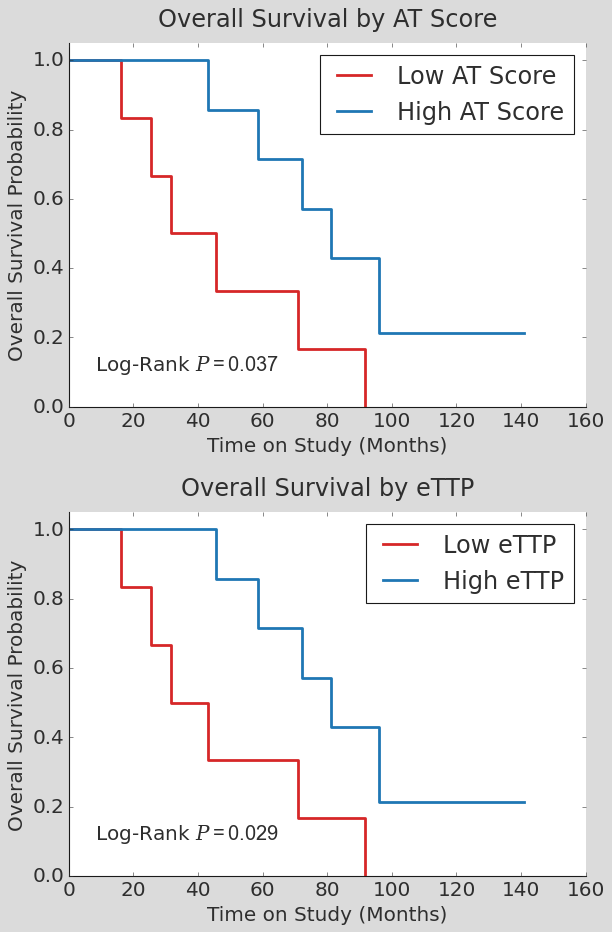

In [121]:
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

# Initialize figure
plt.rcParams['font.size'] = 18
fig, axes = plt.subplots(2, 1, figsize=(8, 12))

# Define medians
median_at = merged_df['AT_Score'].median()
median_ettp = merged_df['Clinical_Preds'].median()

# Create boolean masks for High/Low groups
mask_at_high = merged_df['AT_Score'] >= median_at
mask_ettp_high = merged_df['Clinical_Preds'] >= median_ettp

# Initialize Kaplan-Meier Fitters
kmf_high = KaplanMeierFitter()
kmf_low = KaplanMeierFitter()

# ---------------------------------------------------------
# Plot 1: AT Score (Overall Survival)
# ---------------------------------------------------------
ax1 = axes[0]
# Fit and plot Low AT Score
kmf_low.fit(merged_df[~mask_at_high]['OS_time'], 
            event_observed=merged_df[~mask_at_high]['OS_event'], 
            label='Low AT Score')
kmf_low.plot_survival_function(ax=ax1, color='#d62728', linewidth=2.5, ci_show=False)

# Fit and plot High AT Score
kmf_high.fit(merged_df[mask_at_high]['OS_time'], 
             event_observed=merged_df[mask_at_high]['OS_event'], 
             label='High AT Score')
kmf_high.plot_survival_function(ax=ax1, color='#1f77b4', linewidth=2.5, ci_show=False)

# Run Log-Rank to annotate p-value
res_at = logrank_test(merged_df[mask_at_high]['OS_time'], merged_df[~mask_at_high]['OS_time'], 
                      merged_df[mask_at_high]['OS_event'], merged_df[~mask_at_high]['OS_event'])
ax1.annotate(f'Log-Rank $P = {res_at.p_value:.3f}$', xy=(0.05, 0.1), xycoords='axes fraction', fontsize=18)

ax1.set_title("Overall Survival by AT Score", pad=15)
ax1.set_xlabel("Time on Study (Months)")
ax1.set_ylabel("Overall Survival Probability")
ax1.set_ylim([0.0, 1.05])
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ---------------------------------------------------------
# Plot 2: eTTP (Overall Survival)
# ---------------------------------------------------------
ax2 = axes[1]
# Fit and plot Low eTTP
kmf_low.fit(merged_df[~mask_ettp_high]['OS_time'], 
            event_observed=merged_df[~mask_ettp_high]['OS_event'], 
            label='Low eTTP')
kmf_low.plot_survival_function(ax=ax2, color='#d62728', linewidth=2.5, ci_show=False)

# Fit and plot High eTTP
kmf_high.fit(merged_df[mask_ettp_high]['OS_time'], 
             event_observed=merged_df[mask_ettp_high]['OS_event'], 
             label='High eTTP')
kmf_high.plot_survival_function(ax=ax2, color='#1f77b4', linewidth=2.5, ci_show=False)

# Run Log-Rank to annotate p-value
res_ettp = logrank_test(merged_df[mask_ettp_high]['OS_time'], merged_df[~mask_ettp_high]['OS_time'], 
                        merged_df[mask_ettp_high]['OS_event'], merged_df[~mask_ettp_high]['OS_event'])
ax2.annotate(f'Log-Rank $P = {res_ettp.p_value:.3f}$', xy=(0.05, 0.1), xycoords='axes fraction', fontsize=18)

ax2.set_title("Overall Survival by eTTP", pad=15)
ax2.set_xlabel("Time on Study (Months)")
ax2.set_ylabel("Overall Survival Probability")
ax2.set_ylim([0.0, 1.05])
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("figures/figS_overall_survival_KM.pdf")
plt.show()

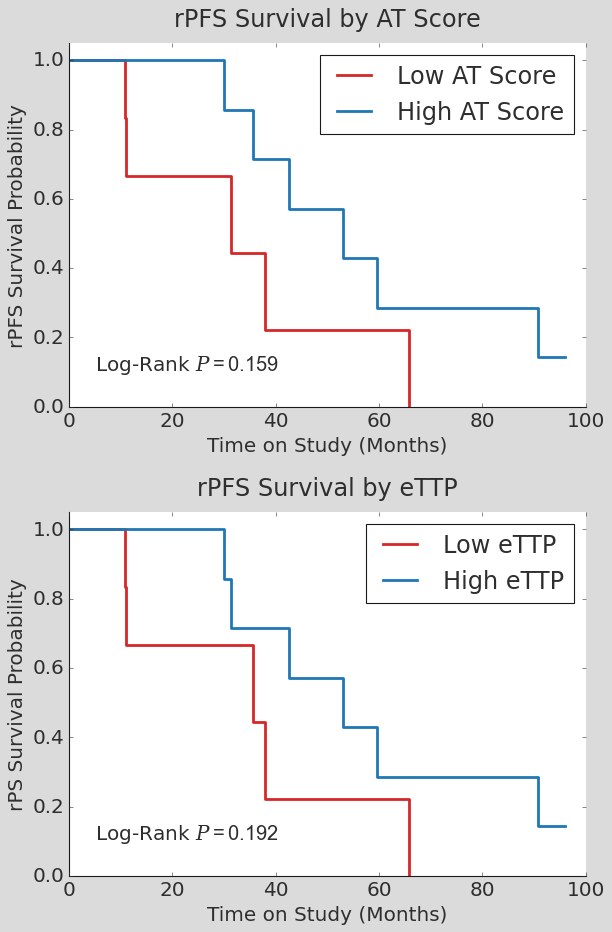

In [122]:
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

# Initialize figure
plt.rcParams['font.size'] = 18
fig, axes = plt.subplots(2, 1, figsize=(8, 12))

# Define medians
median_at = merged_df['AT_Score'].median()
median_ettp = merged_df['Clinical_Preds'].median()

# Create boolean masks for High/Low groups
mask_at_high = merged_df['AT_Score'] >= median_at
mask_ettp_high = merged_df['Clinical_Preds'] >= median_ettp

# Initialize Kaplan-Meier Fitters
kmf_high = KaplanMeierFitter()
kmf_low = KaplanMeierFitter()

# ---------------------------------------------------------
# Plot 1: AT Score (rPS Survival)
# ---------------------------------------------------------
ax1 = axes[0]
# Fit and plot Low AT Score
kmf_low.fit(merged_df[~mask_at_high]['rPFS_time'], 
            event_observed=merged_df[~mask_at_high]['rPFS_event'], 
            label='Low AT Score')
kmf_low.plot_survival_function(ax=ax1, color='#d62728', linewidth=2.5, ci_show=False)

# Fit and plot High AT Score
kmf_high.fit(merged_df[mask_at_high]['rPFS_time'], 
             event_observed=merged_df[mask_at_high]['rPFS_event'], 
             label='High AT Score')
kmf_high.plot_survival_function(ax=ax1, color='#1f77b4', linewidth=2.5, ci_show=False)

# Run Log-Rank to annotate p-value
res_at = logrank_test(merged_df[mask_at_high]['rPFS_time'], merged_df[~mask_at_high]['rPFS_time'], 
                      merged_df[mask_at_high]['rPFS_event'], merged_df[~mask_at_high]['rPFS_event'])
ax1.annotate(f'Log-Rank $P = {res_at.p_value:.3f}$', xy=(0.05, 0.1), xycoords='axes fraction', fontsize=18)

ax1.set_title("rPFS Survival by AT Score", pad=15)
ax1.set_xlabel("Time on Study (Months)")
ax1.set_ylabel("rPFS Survival Probability")
ax1.set_ylim([0.0, 1.05])
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ---------------------------------------------------------
# Plot 2: eTTP (rPS Survival)
# ---------------------------------------------------------
ax2 = axes[1]
# Fit and plot Low eTTP
kmf_low.fit(merged_df[~mask_ettp_high]['rPFS_time'], 
            event_observed=merged_df[~mask_ettp_high]['rPFS_event'],
            label='Low eTTP')
kmf_low.plot_survival_function(ax=ax2, color='#d62728', linewidth=2.5, ci_show=False)

# Fit and plot High eTTP
kmf_high.fit(merged_df[mask_ettp_high]['rPFS_time'], 
             event_observed=merged_df[mask_ettp_high]['rPFS_event'], 
             label='High eTTP')
kmf_high.plot_survival_function(ax=ax2, color='#1f77b4', linewidth=2.5, ci_show=False)

# Run Log-Rank to annotate p-value
res_ettp = logrank_test(merged_df[mask_ettp_high]['rPFS_time'], merged_df[~mask_ettp_high]['rPFS_time'], 
                        merged_df[mask_ettp_high]['rPFS_event'], merged_df[~mask_ettp_high]['rPFS_event'])
ax2.annotate(f'Log-Rank $P = {res_ettp.p_value:.3f}$', xy=(0.05, 0.1), xycoords='axes fraction', fontsize=18)

ax2.set_title("rPFS Survival by eTTP", pad=15)
ax2.set_xlabel("Time on Study (Months)")
ax2.set_ylabel("rPS Survival Probability")
ax2.set_ylim([0.0, 1.05])
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("figures/figS_rPFS_survival_KM.pdf")
plt.show()

In [123]:
from lifelines.statistics import logrank_test

# Define the standard clinical biomarkers to benchmark against
standard_biomarkers = [
    'Baseline_Tumor_Burden', 
    'PSA_Nadir', 
    'Time_to_Nadir', 
    'PSA_Doubling_Time_days'
]

print("--- Overall Survival (OS) Log-Rank Tests (Median Split) ---")
print(f"{'Biomarker':<25} | {'p-value':<10}")
print("-" * 40)

for biomarker in standard_biomarkers:
    # Drop NaNs just in case any standard biomarkers have missing values
    valid_df = merged_df.dropna(subset=[biomarker, 'OS_time', 'OS_event'])
    
    median_val = valid_df[biomarker].median()
    mask_high = valid_df[biomarker] >= median_val
    
    res_os = logrank_test(
        valid_df[mask_high]['OS_time'], 
        valid_df[~mask_high]['OS_time'], 
        event_observed_A=valid_df[mask_high]['OS_event'], 
        event_observed_B=valid_df[~mask_high]['OS_event']
    )
    print(f"{biomarker:<25} | {res_os.p_value:.4f}")

print("\n--- Radiographic PFS (rPFS) Log-Rank Tests (Median Split) ---")
print(f"{'Biomarker':<25} | {'p-value':<10}")
print("-" * 40)

for biomarker in standard_biomarkers:
    valid_df = merged_df.dropna(subset=[biomarker, 'rPFS_time', 'rPFS_event'])
    
    median_val = valid_df[biomarker].median()
    mask_high = valid_df[biomarker] >= median_val
    
    res_rpfs = logrank_test(
        valid_df[mask_high]['rPFS_time'], 
        valid_df[~mask_high]['rPFS_time'], 
        event_observed_A=valid_df[mask_high]['rPFS_event'], 
        event_observed_B=valid_df[~mask_high]['rPFS_event']
    )
    print(f"{biomarker:<25} | {res_rpfs.p_value:.4f}")

--- Overall Survival (OS) Log-Rank Tests (Median Split) ---
Biomarker                 | p-value   
----------------------------------------
Baseline_Tumor_Burden     | 0.6378
PSA_Nadir                 | 0.9281
Time_to_Nadir             | 0.6751
PSA_Doubling_Time_days    | 0.5922

--- Radiographic PFS (rPFS) Log-Rank Tests (Median Split) ---
Biomarker                 | p-value   
----------------------------------------
Baseline_Tumor_Burden     | 0.3304
PSA_Nadir                 | 0.8613
Time_to_Nadir             | 0.4766
PSA_Doubling_Time_days    | 0.3487
